# Задача 10. Байесовская реконструкция

Сначала генерируется один вектор наблюдений $q_i$ — числа
фотоэлектронов на каждом ФЭУ. Для гладкой геометрической модели

$$\mu_i=aYE\,\frac{A\cos\gamma_i}{4\pi d_i^2}
\exp(-d_i/L),\qquad q_i\sim\mathrm{Poisson}(\mu_i).$$

Затем тот же вектор используется как `observed` в PyMC.
Неизвестны энергия и три координаты события; их совместное
апостериорное распределение исследуется NUTS.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

from model import (
    Detector, Source, sample_pmt_photoelectrons,
    expected_pmt_photoelectrons,
)

detector = Detector(R=2.0, N=40, r=0.10, a=0.5)
true_energy = 1.25
true_position = np.array([0.40, -0.30, 0.50])
attenuation_length = 8.0
source = Source(Y=10_000.0, position=true_position)
observed = sample_pmt_photoelectrons(
    detector, source, true_energy, np.random.default_rng(10001),
    attenuation_length=attenuation_length,
)

print("Истинная энергия, МэВ:", true_energy)
print("Истинное положение, м:", true_position)
print("Наблюдаемый полный заряд:", observed.sum())
print("Ненулевых каналов:", np.count_nonzero(observed), "из", detector.N)

Истинная энергия, МэВ: 1.25
Истинное положение, м: [ 0.4 -0.3  0.5]
Наблюдаемый полный заряд: 127
Ненулевых каналов: 34 из 40


In [2]:
centers = detector.unit_centers
area = np.pi * detector.r**2

with pm.Model() as reconstruction_model:
    energy = pm.LogNormal("energy", mu=np.log(1.0), sigma=0.45)
    radius = pm.Uniform("radius", lower=0.0, upper=1.6)
    cos_theta = pm.Uniform("cos_theta", lower=-1.0, upper=1.0)
    phi = pm.Uniform("phi", lower=-np.pi, upper=np.pi)

    sin_theta = pm.math.sqrt(1.0 - cos_theta**2)
    x = pm.Deterministic("x", radius * sin_theta * pm.math.cos(phi))
    y = pm.Deterministic("y", radius * sin_theta * pm.math.sin(phi))
    z = pm.Deterministic("z", radius * cos_theta)

    dx = detector.R * centers[:, 0] - x
    dy = detector.R * centers[:, 1] - y
    dz = detector.R * centers[:, 2] - z
    distance = pm.math.sqrt(dx**2 + dy**2 + dz**2)
    incidence = (
        detector.R
        - centers[:, 0] * x
        - centers[:, 1] * y
        - centers[:, 2] * z
    ) / distance
    probability = area * incidence / (4.0 * np.pi * distance**2)
    probability = probability * pm.math.exp(
        -distance / attenuation_length
    )
    mean_pe = detector.a * source.Y * energy * probability + 1e-9
    pm.Poisson("charge", mu=mean_pe, observed=observed)

    trace = pm.sample(
        draws=800, tune=800, chains=2, cores=1,
        target_accept=0.92, random_seed=10002,
        progressbar=False,
    )

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [energy, radius, cos_theta, phi]


Sampling 2 chains for 800 tune and 800 draw iterations (1_600 + 1_600 draws total) took 0 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


In [3]:
summary = az.summary(
    trace, var_names=["energy", "x", "y", "z"],
    ci_prob=0.94, round_to=3,
)
print(summary)

posterior = trace.posterior
estimates = np.array([
    posterior["x"].values.mean(),
    posterior["y"].values.mean(),
    posterior["z"].values.mean(),
])
energy_estimate = posterior["energy"].values.mean()
print(f"\nE = {energy_estimate:.3f} МэВ (истина {true_energy:.3f})")
print("r =", np.round(estimates, 3), "м; истина", true_position)
print("Ошибка положения:", np.linalg.norm(estimates - true_position), "м")

         mean     sd  eti94_lb  eti94_ub  ess_bulk  ess_tail  r_hat  \
energy  1.264  0.116     1.053     1.490  1514.774   970.846  1.001   
x       0.556  0.122     0.312     0.778  1215.403   819.026  0.999   
y      -0.428  0.108    -0.630    -0.228  1660.017   932.072  1.006   
z       0.547  0.111     0.343     0.750  1688.927  1135.466  1.000   

        mcse_mean  mcse_sd  
energy      0.003    0.003  
x           0.004    0.004  
y           0.003    0.003  
z           0.003    0.003  

E = 1.264 МэВ (истина 1.250)
r = [ 0.556 -0.428  0.547] м; истина [ 0.4 -0.3  0.5]
Ошибка положения: 0.20681648207786796 м


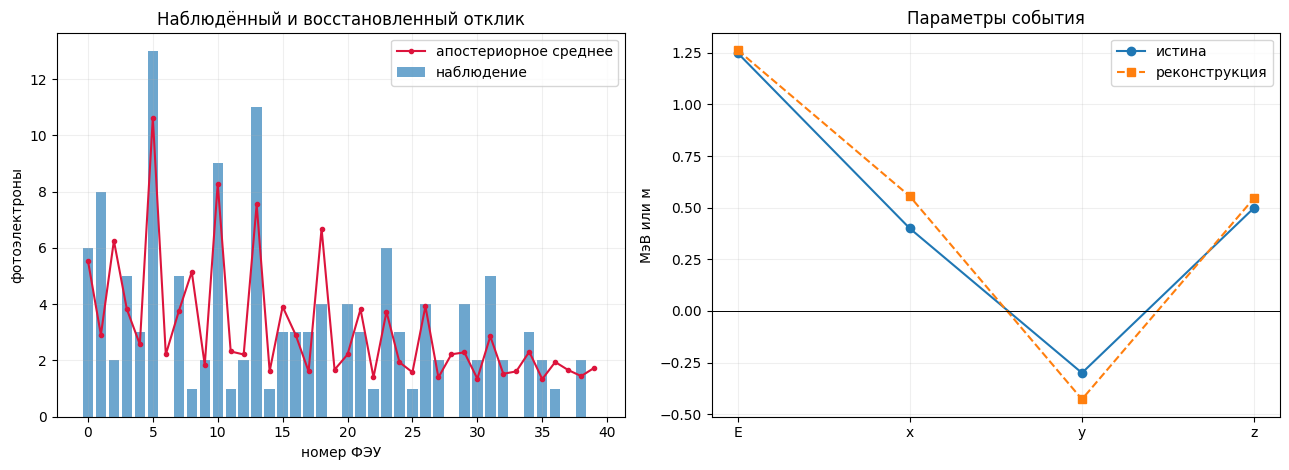

In [4]:
estimated_source = Source(Y=source.Y, position=estimates)
fitted_mean = expected_pmt_photoelectrons(
    detector, estimated_source, energy_estimate,
    attenuation_length=attenuation_length,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
channels = np.arange(detector.N)
axes[0].bar(channels, observed, alpha=0.65, label="наблюдение")
axes[0].plot(channels, fitted_mean, "o-", color="crimson",
             markersize=3, label="апостериорное среднее")
axes[0].set(xlabel="номер ФЭУ", ylabel="фотоэлектроны",
            title="Наблюдённый и восстановленный отклик")
axes[0].legend()
axes[0].grid(alpha=0.2)

labels = ["E", "x", "y", "z"]
truth = np.r_[true_energy, true_position]
estimate = np.r_[energy_estimate, estimates]
axes[1].plot(labels, truth, "o-", label="истина")
axes[1].plot(labels, estimate, "s--", label="реконструкция")
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set(title="Параметры события", ylabel="МэВ или м")
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
fig.savefig("figures/task10_bayesian_reconstruction.png", dpi=180,
            bbox_inches="tight")
plt.show()

assert abs(energy_estimate - true_energy) < 0.25
assert np.linalg.norm(estimates - true_position) < 0.35
assert np.all(summary["r_hat"] < 1.05)

**Вывод.** Апостериорные средние восстанавливают как энергию,
так и положение с точностью, согласующейся с шириной
доверительных интервалов. Значения $\hat R$ близки к единице,
что подтверждает согласованность двух цепей.